# Difference Uncertainty Decomposition Analysis (TU = H_final, AU = H_mix [Class Ka*], EU = Delta H [Class Ke*])

This notebook implements the **Difference Uncertainty Decomposition** formulation parameterized by **Parameter Size-Class Optimal Horizons**:
- **Small Class (1.5B – 3B):** $K_a^* = 2, K_e^* = 27$ (captures sharp aleatoric peak at top layers for Qwen-1.5B/3B and deep epistemic drift)
- **Mid-Size Class (7B – 8B):** $K_a^* = 12, K_e^* = 28$ (captures broader aleatoric plateau peaking at $K_a=12$ with AUROC = 0.652 on Qwen-7B and 0.648 on Llama-3-8B)
- **Large Class (14B+):** $K_a^* = 3, K_e^* = 32$ (captures peak aleatoric AUROC = 0.695 on Qwen-14B and maximum difference horizon AUROC = 0.659)

### Decomposition Formulation:
* **Total Uncertainty ($TU$):** Single-Layer Final Output Entropy $H_{\text{final}}$
* **Aleatoric Uncertainty ($AU$):** Optimal Multi-Layer Premature Ensembled Mixture Entropy $H_{\text{mix}}$ ($K_a^*$) and Semantic Entropy Baselines
* **Epistemic Uncertainty ($EU$):** Difference Epistemic Uncertainty $\Delta H = H_{\text{final}} - H_{\text{mix}}^{(K_e^*)}$
* **Additive Decomposition Identity:**
  $$\text{AU} + \text{EU} = H_{\text{mix}}^{(K_a^*)} + (H_{\text{final}} - H_{\text{mix}}^{(K_e^*)})$$


In [1]:
import os
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import glob
import pickle as pkl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import KFold
import warnings
warnings.filterwarnings('ignore')
import seaborn as sns


## 1. Directory Scanning & Setup

In [2]:
# Configuration - Candidate directories (Unified prioritized, followed by entropies3 and entropies2)
CANDIDATES = [
    '../experiments/result/entropies_unified',
    'src/experiments/result/entropies_unified',
    './result/entropies_unified',
    '../../result/entropies_unified',
    'result/entropies_unified',
    'entropies_unified',
    'src/experiments',
    '../experiments',
    './src/experiments',
    '../experiments/result/entropies3',
    '../experiments/results/entropies3',
    'src/experiments/result/entropies3',
    'src/experiments/results/entropies3',
    './result/entropies3',
    '../../result/entropies3',
    'result/entropies3',
    'entropies3',
    '../experiments/result/entropies2',
    '../experiments/results/entropies2',
    'src/experiments/result/entropies2',
    'src/experiments/results/entropies2',
    './result/entropies2',
    '../../result/entropies2',
    'result/entropies2',
    'entropies2',
    'src/temp',
    './src/temp',
    '../src/temp',
    'src',
    './src',
    '.'
]

valid_dirs = []
for c in CANDIDATES:
    if os.path.exists(c) and any(f.endswith('.pkl') for f in os.listdir(c)):
        abs_c = os.path.abspath(c)
        if abs_c not in valid_dirs:
            valid_dirs.append(abs_c)

DATA_DIR = valid_dirs[0] if valid_dirs else '.'
print(f"Primary Data Directory: {DATA_DIR}")
print(f"All Valid Candidate Directories: {valid_dirs}")

GLOBAL_CORR_THRESHOLD = 0.1
EVAL_LABEL_KEY = 'bleurt'

# Discover all run files dynamically across valid directories in priority order
runs = []
seen_run_keys = set()

for d_path in valid_dirs:
    d_files = glob.glob(os.path.join(d_path, "*.pkl"))
    entropy_files = [f for f in d_files if "_entropies_" in os.path.basename(f) or os.path.basename(f).startswith("sdlg_entropies_")]
    for f in sorted(entropy_files):
        base = os.path.basename(f)
        label_file = f.replace("_entropies_", "_label_").replace("sdlg_entropies_", "sdlg_label_")
        if not os.path.exists(label_file):
            if 'qwen-1.5b' in label_file: label_file = label_file.replace('qwen-1.5b', 'qwen2.5-1.5b')
            elif 'qwen2.5-1.5b' in label_file: label_file = label_file.replace('qwen2.5-1.5b', 'qwen-1.5b')
        question_file = f.replace("_entropies_", "_question_").replace("sdlg_entropies_", "sdlg_question_")
        parts = base.replace(".pkl", "").split("_")
        model_name = "unknown"
        dataset_name = "truthfulqa"
        is_quantized = any(p.lower() == '4bit' or p.lower().endswith('4bit') for p in parts) or ('4bit' in base.lower())
        
        for p in parts:
            p_lower = p.lower()
            if any(m in p_lower for m in ['llama', 'qwen', 'phi', 'opt', 'mistral', 'gemma', 'deepseek']):
                model_name = p
            if any(d in p_lower for d in ['truth', 'sciq', 'openbook', 'open', 'science', 'scienceqa', 'ambig', 'asqa', 'fresh', 'freshqa']):
                dataset_name = 'scienceqa' if 'science' in p_lower or 'sciq' in p_lower else ('openbookqa' if 'open' in p_lower else ('freshqa' if 'fresh' in p_lower else ('asqa' if ('asqa' in p_lower or 'ambig' in p_lower) else ('truthfulqa' if 'truth' in p_lower else p_lower))))
                
        if os.path.exists(label_file):
            display_model = f"{model_name} (4-bit)" if is_quantized and "(4-bit)" not in model_name else model_name
            run_key = (dataset_name.lower(), model_name.lower(), is_quantized)
            if run_key not in seen_run_keys:
                seen_run_keys.add(run_key)
                runs.append({
                    'name': f"{display_model} on {dataset_name}",
                    'model': display_model,
                    'raw_model': model_name,
                    'dataset': dataset_name,
                    'is_quantized': is_quantized,
                    'precision': '4-bit' if is_quantized else 'Full-Precision',
                    'entropy_file': f,
                    'label_file': label_file,
                    'question_file': question_file if os.path.exists(question_file) else None,
                    'dir': d_path
                })

runs_fp = [r for r in runs if not r.get('is_quantized', False)]
runs_quantized = [r for r in runs if r.get('is_quantized', False)]

print(f"Discovered {len(runs)} valid evaluation runs across datasets:")
print(f"  - Full-Precision Runs (Standard FP16/BF16): {len(runs_fp)}")
print(f"  - 4-Bit Quantized Runs                    : {len(runs_quantized)}")

print("\n--- Full-Precision Runs ---")
for r in runs_fp:
    print(f"  - [{r['dataset']}] {r['model']} (from {os.path.basename(r['dir'])})")

if runs_quantized:
    print("\n--- 4-Bit Quantized Runs ---")
    for r in runs_quantized:
        print(f"  - [{r['dataset']}] {r['model']} (from {os.path.basename(r['dir'])})")


Primary Data Directory: /notebooks/modeified_sdlg/src/experiments/result/entropies_unified
All Valid Candidate Directories: ['/notebooks/modeified_sdlg/src/experiments/result/entropies_unified', '/notebooks/modeified_sdlg/src/experiments/result/entropies3', '/notebooks/modeified_sdlg/src/experiments/result/entropies2']
Discovered 44 valid evaluation runs across datasets:
  - Full-Precision Runs (Standard FP16/BF16): 27
  - 4-Bit Quantized Runs                    : 17

--- Full-Precision Runs ---
  - [openbookqa] llama-3.2-1b (from entropies_unified)
  - [openbookqa] llama-3.2-3b (from entropies_unified)
  - [openbookqa] meta-llama-3-8b (from entropies_unified)
  - [openbookqa] phi-3-medium-4k (from entropies_unified)
  - [openbookqa] phi-3-mini-4k (from entropies_unified)
  - [openbookqa] qwen-1.5b (from entropies_unified)
  - [openbookqa] qwen2.5-14b (from entropies_unified)
  - [openbookqa] qwen2.5-3b (from entropies_unified)
  - [openbookqa] qwen2.5-7b (from entropies_unified)
  - [

## 2. Helper to Build Run Dataframe & Grouped Styling

In [3]:
MODEL_CLASS_HORIZONS = {
    'xlarge': {'class': '70B+ (70B-72B)', 'Ka': 2, 'Ke': 60},
    'large':  {'class': 'Large (14B+)',   'Ka': 3, 'Ke': 32},
    'mid':    {'class': 'Mid (7B-8B)',     'Ka': 12, 'Ke': 28},
    'small':  {'class': 'Small (1.5B-3B)', 'Ka': 2, 'Ke': 27}
}

def get_model_class_and_horizons(model_name):
    m = str(model_name).lower().replace('_', '-')
    if any(s in m for s in ['70b', '72b']):
        return '70B+ (70B-72B)', 2, 60
    elif any(s in m for s in ['14b', 'phi-3-medium']):
        return 'Large (14B+)', 3, 32
    elif any(s in m for s in ['7b', '8b']):
        return 'Mid (7B-8B)', 12, 28
    else:
        return 'Small (1.5B-3B)', 2, 27

def safe_extract_label(val, key='bleurt'):
    while isinstance(val, (list, tuple)) and len(val) > 0: val = val[0]
    if isinstance(val, dict):
        if key in val: val = val[key]
        elif 'correctness_dict' in val: val = val['correctness_dict'].get(key, 0.0)
        else:
            for k in ['bleurt_score', 'bleurt', 'rougeL', 'rouge1', 'exact_match']:
                if k in val: val = val[k]; break
            else: val = 0.0
    try:
        fval = float(val)
        return fval if np.isfinite(fval) else 0.0
    except Exception:
        return 0.0

def _to_fixed_array(chunk_or_list, key, N):
    if N <= 0: return np.array([], dtype=float)
    if chunk_or_list is None: return np.full(N, np.nan, dtype=float)
    if isinstance(chunk_or_list, list):
        if key is not None:
            raw = [d.get(key, np.nan) if isinstance(d, dict) else np.nan for d in chunk_or_list[:N]]
        else:
            raw = chunk_or_list[:N]
    else:
        raw = list(chunk_or_list)[:N]
    arr = pd.to_numeric(pd.Series(raw), errors='coerce').values
    if len(arr) < N:
        arr = np.pad(arr, (0, N - len(arr)), constant_values=np.nan)
    elif len(arr) > N:
        arr = arr[:N]
    return arr.astype(float)

def _model_aliases(model):
    m = str(model).lower().replace('_', '-').replace('-instruct', '').replace('-chat', '').replace(' (4-bit)', '').replace('(4-bit)', '').replace('-4bit', '').replace('_4bit', '').strip('-')
    aliases = [m, m.replace('-', '_'), m.replace('-', '')]
    if 'meta-' in m:
        aliases.extend([m.replace('meta-', ''), m.replace('meta-', '').replace('-', '')])
    else:
        aliases.append(f"meta-{m}")

    if 'qwen-1.5b' in m or 'qwen2.5-1.5b' in m:
        aliases.extend(['qwen-1.5b', 'qwen2.5-1.5b', 'qwen_1.5b', 'qwen2.5_1.5b', 'qwen2.5-1.5b-instruct', 'qwen1.5b', 'qwen2.5-1.5'])
    if 'qwen-3b' in m or 'qwen2.5-3b' in m:
        aliases.extend(['qwen-3b', 'qwen2.5-3b', 'qwen_3b', 'qwen2.5_3b', 'qwen2.5-3b-instruct', 'qwen3b', 'qwen2.5-3'])
    if 'qwen-7b' in m or 'qwen2.5-7b' in m:
        aliases.extend(['qwen-7b', 'qwen2.5-7b', 'qwen_7b', 'qwen2.5_7b', 'qwen2.5-7b-instruct', 'qwen7b', 'qwen2.5-7'])
    if 'qwen-14b' in m or 'qwen2.5-14b' in m:
        aliases.extend(['qwen-14b', 'qwen2.5-14b', 'qwen_14b', 'qwen2.5_14b', 'qwen2.5-14b-instruct', 'qwen14b', 'qwen2.5-14'])
    if 'qwen1.5-moe' in m or 'qwen-moe' in m or 'moe' in m:
        aliases.extend(['qwen1.5-moe-a2.7b', 'qwen1.5_moe_a2.7b', 'qwen1.5-moe', 'qwen_moe', 'qwen1.5-moe-chat', 'moe-a2.7b'])
    if 'llama-3.2-3b' in m or 'llama3.2-3b' in m:
        aliases.extend(['llama-3.2-3b', 'llama3.2-3b', 'llama-3-3b', 'llama-3.2-3b-instruct', 'llama3.2_3b', 'llama-3.2', 'llama3.2'])
    if 'llama-3-8b' in m or 'meta-llama-3-8b' in m or 'llama3-8b' in m or 'llama-8b' in m or 'llama8b' in m:
        aliases.extend(['llama-3-8b', 'llama3-8b', 'meta-llama-3-8b', 'meta-llama-3-8b-instruct', 'llama-3-8b-instruct', 'llama-8b', 'llama8b', 'meta-llama-3.1-8b', 'llama-3.1-8b', 'llama3.1-8b', 'meta-llama-3', 'llama3'])
    if 'phi-3-mini' in m or 'phi-3-mini-4k' in m or 'phi-3' in m:
        aliases.extend(['phi-3-mini-4k', 'phi-3-mini', 'phi-3', 'phi-3-mini-4k-instruct', 'phi3'])
    if 'phi-3-medium' in m or 'phi-3-medium-4k' in m:
        aliases.extend(['phi-3-medium-4k', 'phi-3-medium', 'phi-3-medium-4k-instruct', 'phi3-medium'])
    if '70b' in m or 'llama-3.1-70b' in m or 'llama-70b' in m:
        aliases.extend(['llama-3.1-70b', 'llama-70b', 'llama3.1-70b', 'llama-3.1-70b-instruct', 'llama3.1_70b', 'llama70b', 'llama-3.1-70b_4bit', 'llama-3.1-70b-4bit'])
    if '72b' in m or 'qwen2.5-72b' in m or 'qwen-72b' in m:
        aliases.extend(['qwen2.5-72b', 'qwen-72b', 'qwen2.5_72b', 'qwen2.5-72b-instruct', 'qwen72b', 'qwen2.5-72b_4bit', 'qwen2.5-72b-4bit'])
    if 'deepseek' in m:
        aliases.extend(['deepseek-moe-16b', 'deepseek_moe_16b', 'deepseek-moe-16b-chat', 'deepseek-moe', 'deepseek'])
    base_aliases = list(set(aliases))
    for a in base_aliases:
        aliases.extend([f"{a}_4bit", f"{a}-4bit", f"{a}_4_bit", f"{a}-4-bit"])
    return list(set(aliases))

def _dataset_aliases(dataset):
    d = str(dataset).lower().replace('_', '-')
    aliases = [d, d.replace('-', '_')]
    if any(t in d for t in ['truth', 'truthful', 'truthfulqa']):
        aliases.extend(['truth', 'truthful', 'truthfulqa', 'truthful_qa'])
    elif any(s in d for s in ['science', 'scienceqa', 'sciq']):
        aliases.extend(['science', 'scienceqa', 'science_qa', 'sciq'])
    elif any(o in d for o in ['open', 'openbook', 'openbookqa']):
        aliases.extend(['open', 'openbook', 'openbookqa', 'openbook_qa'])
    elif any(f in d for f in ['fresh', 'freshqa']):
        aliases.extend(['fresh', 'freshqa', 'fresh_qa'])
    elif any(a in d for a in ['asqa', 'ambig']):
        aliases.extend(['asqa', 'ambig', 'asqa_long'])
    base_aliases = list(set(aliases))
    for a in base_aliases:
        aliases.extend([f"{a}_4bit", f"{a}-4bit", f"{a}_4_bit", f"{a}-4-bit"])
    return list(set(aliases))

def resolve_metric_candidates(chunk, candidate_keys, N):
    if not chunk or N <= 0: return np.full(N, np.nan, dtype=float)
    if isinstance(candidate_keys, str): candidate_keys = [candidate_keys]
    first_d = next((d for d in chunk if isinstance(d, dict)), {})
    for ck in candidate_keys:
        if ck in first_d or any(isinstance(d, dict) and ck in d for d in chunk[:N]):
            vals = [d.get(ck, np.nan) if isinstance(d, dict) else np.nan for d in chunk[:N]]
            return _to_fixed_array(vals, None, N)
    base_key = candidate_keys[0]
    alts = [k for k in first_d.keys() if k.startswith(f"{base_key}_") or base_key in k]
    if alts:
        alts.sort(key=lambda x: int(x.split('_')[-1]) if x.split('_')[-1].isdigit() else 999)
        vals = [d.get(alts[0], np.nan) if isinstance(d, dict) else np.nan for d in chunk[:N]]
        return _to_fixed_array(vals, None, N)
    return np.full(N, np.nan, dtype=float)

def load_run_data(run):
    with open(run['entropy_file'], 'rb') as f: raw_entropies = pkl.load(f)
    with open(run['label_file'], 'rb') as f: raw_labels = pkl.load(f)
    
    questions = []
    if run.get('question_file') and os.path.exists(run['question_file']):
        try:
            with open(run['question_file'], 'rb') as f: questions = pkl.load(f)
        except Exception:
            pass
            
    raw_labels_len = len(raw_labels)
    raw_ent_len = len(raw_entropies) if isinstance(raw_entropies, list) else 0
    
    if raw_ent_len >= int(2.5 * raw_labels_len) and raw_labels_len > 0:
        num_instances = raw_labels_len
        ours_entropies = raw_entropies[0 : num_instances]
        sdlg_entropies = raw_entropies[num_instances : 2*num_instances]
        kuhn_entropies = raw_entropies[2*num_instances : 3*num_instances]
    else:
        num_instances = min(raw_labels_len, raw_ent_len) if raw_ent_len > 0 else raw_labels_len
        ours_entropies = raw_entropies[0 : num_instances] if raw_ent_len >= num_instances else []
        sdlg_entropies = None
        kuhn_entropies = None

    m_aliases = _model_aliases(run.get('model', ''))
    d_aliases = _dataset_aliases(run.get('dataset', 'truthfulqa'))
    
    # 1. HYBRID FALLBACK: If SE chunks are missing (e.g. DATA_DIR is entropies3 or entropies_unified), lookup entropies2
    has_se = (ours_entropies and any(isinstance(d, dict) and 'normalised_semantic_entropy' in d for d in ours_entropies))
    if sdlg_entropies is None or kuhn_entropies is None or not has_se:
        candidate_e2_dirs = [
            '../experiments/result/entropies2',
            '../experiments/results/entropies2',
            'src/experiments/result/entropies2',
            'src/experiments/results/entropies2',
            './result/entropies2',
            '../../result/entropies2',
            '../experiments/result/entropies3',
            'src/experiments/result/entropies3',
            'result/entropies2',
            'result/entropies3',
            'entropies2',
            'entropies3',
            'src/temp',
            './src/temp',
            '../src/temp'
        ]
        for e2_dir in candidate_e2_dirs:
            if not os.path.exists(e2_dir): continue
            for fname in os.listdir(e2_dir):
                fl = fname.lower()
                if ('_entropies_' in fl or fl.startswith('sdlg_entropies_')) and any(ma in fl for ma in m_aliases) and any(da in fl for da in d_aliases):
                    e2_path = os.path.join(e2_dir, fname)
                    if os.path.abspath(e2_path) == os.path.abspath(run['entropy_file']):
                        continue
                    try:
                        with open(e2_path, 'rb') as fp: e2_raw = pkl.load(fp)
                        if isinstance(e2_raw, list) and len(e2_raw) >= int(2.5 * num_instances):
                            if sdlg_entropies is None: sdlg_entropies = e2_raw[num_instances : 2*num_instances]
                            if kuhn_entropies is None: kuhn_entropies = e2_raw[2*num_instances : 3*num_instances]
                            if not has_se:
                                ours_se_c = e2_raw[0:num_instances]
                                for idx_i in range(min(len(ours_entropies), len(ours_se_c))):
                                    if isinstance(ours_entropies[idx_i], dict) and isinstance(ours_se_c[idx_i], dict) and 'normalised_semantic_entropy' in ours_se_c[idx_i]:
                                        ours_entropies[idx_i]['normalised_semantic_entropy'] = ours_se_c[idx_i]['normalised_semantic_entropy']
                                has_se = True
                            break
                        elif isinstance(e2_raw, list) and len(e2_raw) >= num_instances and not has_se:
                            ours_se_c = e2_raw[0:num_instances]
                            if any(isinstance(d, dict) and 'normalised_semantic_entropy' in d for d in ours_se_c):
                                for idx_i in range(min(len(ours_entropies), len(ours_se_c))):
                                    if isinstance(ours_entropies[idx_i], dict) and isinstance(ours_se_c[idx_i], dict) and 'normalised_semantic_entropy' in ours_se_c[idx_i]:
                                        ours_entropies[idx_i]['normalised_semantic_entropy'] = ours_se_c[idx_i]['normalised_semantic_entropy']
                                has_se = True
                    except Exception:
                        pass
            if sdlg_entropies is not None and kuhn_entropies is not None and has_se:
                break

    labels = _to_fixed_array([safe_extract_label(l, EVAL_LABEL_KEY) for l in raw_labels[:num_instances]], None, num_instances)
    our_se = _to_fixed_array(ours_entropies, 'normalised_semantic_entropy', num_instances)
    sdlg_se = _to_fixed_array(sdlg_entropies, 'normalised_semantic_entropy', num_instances) if sdlg_entropies is not None else our_se
    kuhn_se = _to_fixed_array(kuhn_entropies, 'normalised_semantic_entropy', num_instances)
    q_list = questions[:num_instances] if len(questions) >= num_instances else (questions + [f"Q{i}" for i in range(len(questions), num_instances)])

    model_class, ka_depth, ke_depth = get_model_class_and_horizons(run['model'])
    ka_candidates = [f'entropy_mixture_top_{ka_depth}', f'entropy_mixture_{ka_depth-1}', f'entropy_mixture_depth_{ka_depth}', f'entropy_mixture_{ka_depth}', 'entropy_mixture_top_2', 'entropy_mixture_2', 'entropy_mixture']
    ke_candidates = [f'entropy_mixture_top_{ke_depth}', f'entropy_mixture_{ke_depth-1}', f'entropy_mixture_depth_{ke_depth}', f'entropy_mixture_{ke_depth}', 'entropy_mixture_top_16', 'entropy_mixture_16', 'entropy_mixture']
    h_final_calc = resolve_metric_candidates(ours_entropies, ['entropy_final', 'entropy_final_top_8'], num_instances)
    h_mix_ka_calc = resolve_metric_candidates(ours_entropies, ka_candidates, num_instances)
    h_mix_ke_calc = resolve_metric_candidates(ours_entropies, ke_candidates, num_instances)
    ep_diff_calc = h_final_calc - h_mix_ke_calc

    df = pd.DataFrame({
        'Question': q_list[:num_instances],
        'Correctness': labels,
        'Is_Correct': (pd.Series(labels) >= GLOBAL_CORR_THRESHOLD).astype(int),
        'Our_Weighted_SE': our_se,
        'entropy_final': h_final_calc,
        'entropy_mixture': h_mix_ka_calc,
        'epistemic_diff': ep_diff_calc,
        'epistemic_diff_clipped': np.maximum(0.0, ep_diff_calc),
        'mutual_info': resolve_metric_candidates(ours_entropies, ['mutual_info_top_16', 'mutual_info_16', 'mutual_info_depth_16', 'mutual_info_15', 'mutual_info', 'mutual_info_top_8'], num_instances),
        'mutual_info_top_16': resolve_metric_candidates(ours_entropies, ['mutual_info_top_16', 'mutual_info_16', 'mutual_info_depth_16', 'mutual_info_15', 'mutual_info_top_8', 'mutual_info'], num_instances),
        'gated_mutual_info': resolve_metric_candidates(ours_entropies, ['gated_mutual_info_top_16', 'gated_mutual_info_top_8', 'gated_mutual_info', 'gated_mutual_info_top_24'], num_instances),
        'gated_mutual_info_depth_75': resolve_metric_candidates(ours_entropies, ['gated_mutual_info_depth_75', 'gated_mutual_info_75', 'gated_mutual_info_top_24', 'gated_mutual_info_top_21'], num_instances),
        'jsd': resolve_metric_candidates(ours_entropies, ['jsd_top_16', 'jsd_top_8', 'jsd'], num_instances),
        'kl': resolve_metric_candidates(ours_entropies, ['kl_top_16', 'kl_top_8', 'kl'], num_instances),
        'epkl': resolve_metric_candidates(ours_entropies, ['epkl_top_16', 'epkl_top_8', 'epkl'], num_instances),
        'tvd': resolve_metric_candidates(ours_entropies, ['tvd_top_16', 'tvd_top_8', 'tvd'], num_instances),
        'cv': resolve_metric_candidates(ours_entropies, ['cv_top_16', 'cv_top_8', 'cv'], num_instances),
        'bhattacharyya': resolve_metric_candidates(ours_entropies, ['bhattacharyya_top_16', 'bhattacharyya_top_8', 'bhattacharyya'], num_instances),
        'SDLG_Baseline_SE': sdlg_se,
        'SDLG_SE': sdlg_se,
        'Semantic_Entropy': sdlg_se,
        'Kuhn_Baseline_SE': kuhn_se,
        'Kuhn_SE': kuhn_se,
    })

    # External TokUR and ICE baselines
    candidate_tokur_roots = [
        os.path.join(DATA_DIR, '..', 'tokur', 'result') if DATA_DIR else '.',
        os.path.join(DATA_DIR, '..', 'tokur') if DATA_DIR else '.',
        os.path.join(DATA_DIR, '..', 'entropies_unified') if DATA_DIR else '.',
        './tokur/result', './tokur',
        '../experiments/tokur/result', '../experiments/tokur',
        'src/experiments/tokur/result', 'src/experiments/tokur',
        './result/tokur', 'results/tokur', 'result/tokur',
        'result/entropies_unified', './result/entropies_unified', 'entropies_unified',
        'entropies3', 'entropies2', '.'
    ]
    candidate_ice_roots = [
        os.path.join(DATA_DIR, '..', 'ice', 'result') if DATA_DIR else '.',
        os.path.join(DATA_DIR, '..', 'ice') if DATA_DIR else '.',
        './ice/result', './ice',
        '../experiments/ice/result', '../experiments/ice',
        'src/experiments/ice/result', 'src/experiments/ice',
        './result/ice', 'results/ice', 'result/ice',
        'entropies3', 'entropies2', '.'
    ]

    tokur_found = False
    for troot in candidate_tokur_roots:
        if tokur_found or not os.path.exists(troot): continue
        for root_dir, dirs, files in os.walk(troot):
            sorted_files = sorted(files, key=lambda x: (0 if 'entrop' in x.lower() else (1 if 'tokur' in x.lower() else 2)))
            for fname in sorted_files:
                fl = fname.lower()
                r_lower = root_dir.lower()
                if 'checkpoint' in fl or 'checkpoint' in r_lower:
                    continue
                if ('tokur' in fl or 'tokur' in r_lower) and any(ma in fl or ma in r_lower for ma in m_aliases) and any(da in fl or da in r_lower for da in d_aliases):
                    if fl.endswith('.pkl'):
                        tpath = os.path.join(root_dir, fname)
                        try:
                            with open(tpath, 'rb') as fp: tent = pkl.load(fp)
                            if isinstance(tent, list) and len(tent) > 0:
                                def _ext_tok(e, k1, k2):
                                    if not isinstance(e, dict): return np.nan
                                    sub = e.get('entropy_dict', e) if isinstance(e.get('entropy_dict'), dict) else e
                                    return sub.get(k1, sub.get(k2, np.nan))
                                tok_au = _to_fixed_array([_ext_tok(e, 'tokur_au', 'entropy_final') for e in tent], None, num_instances)
                                tok_mi = _to_fixed_array([_ext_tok(e, 'tokur_mi', 'mutual_info') for e in tent], None, num_instances)
                                if np.isfinite(tok_au).any() or np.isfinite(tok_mi).any():
                                    df['tokur_au'] = tok_au
                                    df['tokur_mi'] = tok_mi
                                    df['tokur_total'] = np.where(np.isfinite(tok_au) & np.isfinite(tok_mi), tok_au + tok_mi, np.nan)
                                    tokur_found = True
                                    break
                        except Exception: pass
            if tokur_found: break

    ice_found = False
    for iroot in candidate_ice_roots:
        if ice_found or not os.path.exists(iroot): continue
        for root_dir, dirs, files in os.walk(iroot):
            for fname in files:
                fl = fname.lower()
                r_lower = root_dir.lower()
                if ('ice' in fl or 'ice' in r_lower) and any(ma in fl or ma in r_lower for ma in m_aliases) and any(da in fl or da in r_lower for da in d_aliases):
                    if fl.endswith('.csv') or fl.endswith('.pkl'):
                        ipath = os.path.join(root_dir, fname)
                        try:
                            idf = pd.read_csv(ipath) if fl.endswith('.csv') else pd.DataFrame(pkl.load(open(ipath, 'rb')))
                            if 'aleatoric_uncertainty' in idf.columns:
                                df['ice_aleatoric'] = _to_fixed_array(idf['aleatoric_uncertainty'].values, None, num_instances)
                            if 'epistemic_uncertainty' in idf.columns:
                                df['ice_epistemic'] = _to_fixed_array(idf['epistemic_uncertainty'].values, None, num_instances)
                            if 'total_uncertainty' in idf.columns:
                                df['ice_total'] = _to_fixed_array(idf['total_uncertainty'].values, None, num_instances)
                            elif 'ice_aleatoric' in df.columns and 'ice_epistemic' in df.columns:
                                df['ice_total'] = df['ice_aleatoric'] + df['ice_epistemic']
                            if 'ice_aleatoric' in df.columns or 'ice_total' in df.columns or 'ice_epistemic' in df.columns:
                                ice_found = True
                                break
                        except Exception: pass
            if ice_found: break

    # Extract layerwise ensembling keys for sweep charts
    first_d = next((d for d in ours_entropies if isinstance(d, dict)), {})
    
    # 1. Map all entropy mixture depths (up to physical model depth <= 48)
    em_found_keys = [k for k in first_d.keys() if ('entropy_mixture' in k) and any(c.isdigit() for c in k)]
    for key in em_found_keys:
        df[key] = _to_fixed_array([d.get(key, 0.0) if isinstance(d, dict) else 0.0 for d in ours_entropies], None, num_instances)
        digits = ''.join(c for c in key.split('_')[-1] if c.isdigit())
        if digits and int(digits) <= 80:
            idx_k = int(digits) - 1 if int(digits) > 0 else 0
            df[f'entropy_mixture_{idx_k}'] = df[key]
            
    # 2. Map all mutual info depths (up to physical model depth <= 48)
    mi_found_keys = [k for k in first_d.keys() if ('mutual_info' in k and 'gated' not in k) and any(c.isdigit() for c in k)]
    for key in mi_found_keys:
        df[key] = _to_fixed_array([d.get(key, 0.0) if isinstance(d, dict) else 0.0 for d in ours_entropies], None, num_instances)
        digits = ''.join(c for c in key.split('_')[-1] if c.isdigit())
        if digits and int(digits) <= 80:
            idx_k = int(digits) - 1 if int(digits) > 0 else 0
            df[f'mutual_info_{idx_k}'] = df[key]

    # 3. Map all gated mutual info depths
    gmi_found_keys = [k for k in first_d.keys() if ('gated_mutual_info' in k) and any(c.isdigit() for c in k)]
    for key in gmi_found_keys:
        df[key] = _to_fixed_array([d.get(key, 0.0) if isinstance(d, dict) else 0.0 for d in ours_entropies], None, num_instances)
        digits = ''.join(c for c in key.split('_')[-1] if c.isdigit())
        if digits and int(digits) <= 80:
            idx_k = int(digits) - 1 if int(digits) > 0 else 0
            df[f'gated_mutual_info_{idx_k}'] = df[key]
            
    return df, raw_entropies, labels

def get_curves_and_metrics(df, uncertainty_col, threshold=GLOBAL_CORR_THRESHOLD):
    df['Is_Correct'] = (df['Correctness'] >= threshold).astype(int)
    u_raw = pd.to_numeric(df[uncertainty_col], errors='coerce')
    c_raw = pd.to_numeric(df['Correctness'], errors='coerce')
    valid_mask = u_raw.notna() & c_raw.notna() & np.isfinite(u_raw) & np.isfinite(c_raw)
    df_clean = df[valid_mask].copy()
    
    if len(df_clean) < 2:
        return [0.0, 1.0], [0.0, 1.0], np.nan, np.nan, np.linspace(0.01, 1.0, 100), [], [], 0.0
        
    correct = df_clean['Is_Correct'].values
    u_val = pd.to_numeric(df_clean[uncertainty_col], errors='coerce').values
    N = len(correct)
    a0 = correct.mean()
    
    try:
        if len(np.unique(correct)) > 1:
            fpr, tpr, _ = roc_curve(1 - correct, u_val)
            auroc = roc_auc_score(1 - correct, u_val)
        else:
            fpr, tpr, auroc = [0.0, 1.0], [0.0, 1.0], 0.500
    except Exception:
        fpr, tpr, auroc = [0.0, 1.0], [0.0, 1.0], 0.500

    try:
        correct_sorted = df_clean.sort_values(by=uncertainty_col, ascending=True)['Is_Correct'].values
        coverages = np.linspace(0.01, 1.0, 100)
        accuracies_method = [correct_sorted[:max(1, int(N * cov))].mean() for cov in coverages]
        accuracies_oracle = [min(max(1, int(N * cov)), correct.sum()) / max(1, int(N * cov)) for cov in coverages]
        area_method = np.trapz(accuracies_method, coverages)
        area_oracle = np.trapz(accuracies_oracle, coverages)
        area_baseline = a0
        prr = (area_method - area_baseline) / (area_oracle - area_baseline + 1e-10)
    except Exception:
        prr = 0.0
        coverages, accuracies_method, accuracies_oracle = np.linspace(0.01, 1.0, 100), [], []
        
    return fpr, tpr, auroc, prr, coverages, accuracies_method, accuracies_oracle, a0

def calculate_auroc_and_prr(df, uncertainty_col, threshold=GLOBAL_CORR_THRESHOLD):
    fpr, tpr, auroc, prr, _, _, _, _ = get_curves_and_metrics(df, uncertainty_col, threshold)
    return auroc, prr

def bold_max_grouped(df):
    if df.empty:
        return df

    try:
        from IPython.display import HTML
    except ImportError:
        class HTML:
            def __init__(self, data): self.data = data
            def _repr_html_(self): return self.data
            def __repr__(self): return self.data

    class StyledBenchmarkTable(HTML):
        def __init__(self, html_str, df=None, styler=None):
            super().__init__(html_str)
            self.df = df
            self.styler = styler
        def to_html(self):
            return self.data

    df_work = df.copy()
    dataset_col = ('Meta', 'Dataset')
    if dataset_col in df_work.columns:
        df_work = df_work.sort_values(by=[dataset_col], kind='stable').reset_index(drop=True)
        datasets = df_work[dataset_col].tolist()
    else:
        datasets = []

    # Dataset spans for vertical column merging and horizontal divider bars
    dataset_spans = []
    dataset_boundary_rows = set()
    if datasets:
        curr_ds = datasets[0]
        start_idx = 0
        for i, ds in enumerate(datasets):
            if ds != curr_ds:
                dataset_spans.append((curr_ds, start_idx, i - start_idx))
                dataset_boundary_rows.add(i - 1)
                curr_ds = ds
                start_idx = i
        dataset_spans.append((curr_ds, start_idx, len(datasets) - start_idx))
        dataset_boundary_rows.add(len(datasets) - 1)

    level0_groups = []
    for col in df_work.columns:
        if col[0] not in level0_groups:
            level0_groups.append(col[0])
            
    boundary_col_indices = []
    for grp in level0_groups[:-1]:
        grp_indices = [i for i, col in enumerate(df_work.columns) if col[0] == grp]
        if grp_indices:
            boundary_col_indices.append(grp_indices[-1])

    def _highlight_max_and_borders(row):
        styles = [''] * len(row)
        row_idx = row.name
        
        # 1. Highlight best (bold + light green) and second best (mild soft blue + underline)
        groups = set(col[0] for col in df_work.columns if col[0] != 'Meta')
        for grp in groups:
            grp_cols = [idx for idx, col in enumerate(df_work.columns) if col[0] == grp]
            vals = [row.iloc[idx] for idx in grp_cols]
            numeric_vals = [
                (idx, v) for idx, v in zip(grp_cols, vals) 
                if pd.notna(v) and isinstance(v, (int, float, np.number)) and np.isfinite(v)
            ]
            if numeric_vals:
                sorted_vals = sorted(list(set(v for _, v in numeric_vals)), reverse=True)
                best_v = sorted_vals[0]
                second_best_v = sorted_vals[1] if len(sorted_vals) > 1 else None
                
                for idx, v in numeric_vals:
                    if abs(v - best_v) < 1e-6:
                        styles[idx] = 'font-weight: bold; background-color: #d4edda; color: #155724;'
                    elif second_best_v is not None and abs(v - second_best_v) < 1e-6:
                        styles[idx] = 'background-color: #e8f0fe; color: #1a4971; text-decoration: underline; font-weight: 500;'

        # 2. Vertical borders between level-0 groups
        for b_idx in boundary_col_indices:
            styles[b_idx] += ' border-right: 2.5px solid #444444;'

        # 3. Horizontal bars between datasets
        if row_idx in dataset_boundary_rows and row_idx != len(df_work) - 1:
            for c_idx in range(len(row)):
                styles[c_idx] += ' border-bottom: 2px solid #444444;'

        return styles

    format_dict = {}
    for col in df_work.columns:
        if col[0] != 'Meta':
            format_dict[col] = '{:.4f}'

    styler = df_work.style
    if hasattr(styler, 'hide'):
        try:
            styler = styler.hide(axis='index')
        except TypeError:
            styler = styler.hide()
    elif hasattr(styler, 'hide_index'):
        styler = styler.hide_index()

    styler = styler.apply(_highlight_max_and_borders, axis=1).format(format_dict, na_rep='-')

    table_styles = [
        {'selector': 'table', 'props': [
            ('border-collapse', 'collapse'), 
            ('width', '100%'), 
            ('border-top', '2.5px solid #333333'), 
            ('border-bottom', '2.5px solid #333333'),
            ('font-family', '-apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, "Helvetica Neue", Arial, sans-serif')
        ]},
        {'selector': 'th', 'props': [
            ('text-align', 'center'), 
            ('font-size', '10.5pt'), 
            ('padding', '6px 8px'),
            ('background-color', '#f1f3f5'),
            ('border-bottom', '1.5px solid #888888')
        ]},
        {'selector': 'td', 'props': [
            ('text-align', 'center'), 
            ('padding', '5px 8px'),
            ('font-size', '10pt'),
            ('border-top', '1px solid #e9ecef')
        ]}
    ]
    for b_idx in boundary_col_indices:
        table_styles.append({
            'selector': f'th.col{b_idx}',
            'props': [('border-right', '2.5px solid #444444 !important')]
        })
    styler = styler.set_table_styles(table_styles, overwrite=False)

    raw_html = styler.to_html()

    if not dataset_spans or dataset_col not in df_work.columns:
        return StyledBenchmarkTable(raw_html, df=df_work, styler=styler)

    # Post-process HTML to merge dataset column cells vertically (rowspan)
    import re
    tbody_match = re.search(r'(<tbody>(.*?)</tbody>)', raw_html, re.DOTALL)
    if not tbody_match:
        return StyledBenchmarkTable(raw_html, df=df_work, styler=styler)

    tbody_full = tbody_match.group(1)
    tbody_content = tbody_match.group(2)
    rows = re.findall(r'(<tr[^>]*>.*?</tr>)', tbody_content, re.DOTALL)

    if len(rows) != len(df_work):
        return StyledBenchmarkTable(raw_html, df=df_work, styler=styler)

    span_start_map = {}
    remove_col0_rows = set()
    for i, (ds_name, start_idx, count) in enumerate(dataset_spans):
        is_last_ds = (i == len(dataset_spans) - 1)
        span_start_map[start_idx] = (count, is_last_ds)
        for r in range(start_idx + 1, start_idx + count):
            remove_col0_rows.add(r)

    new_rows = []
    for r_idx, row_html in enumerate(rows):
        if r_idx in span_start_map:
            count, is_last_ds = span_start_map[r_idx]
            border_btm = ' border-bottom: 2px solid #444444;' if not is_last_ds else ''
            
            def repl_col0(match):
                attrs = match.group(1)
                content = match.group(2)
                style_addition = f'vertical-align: middle; text-align: center; font-weight: bold; background-color: #f8f9fa; border-right: 1.5px solid #bbbbbb;{border_btm}'
                if 'style="' in attrs:
                    attrs = re.sub(r'style="([^"]*)"', rf'style="\1; {style_addition}"', attrs)
                else:
                    attrs = f'{attrs} style="{style_addition}"'
                if count > 1:
                    return f'<td{attrs} rowspan="{count}">{content}</td>'
                else:
                    return f'<td{attrs}>{content}</td>'

            row_html = re.sub(r'<td([^>]*_col0[^>]*)>(.*?)</td>', repl_col0, row_html, count=1)
            new_rows.append(row_html)
        elif r_idx in remove_col0_rows:
            row_html = re.sub(r'\s*<td[^>]*_col0[^>]*>.*?</td>', '', row_html, count=1)
            new_rows.append(row_html)
        else:
            new_rows.append(row_html)

    new_tbody_content = '\n'.join(new_rows)
    new_tbody = f'<tbody>\n{new_tbody_content}\n  </tbody>'
    final_html = raw_html.replace(tbody_full, new_tbody)

    return StyledBenchmarkTable(final_html, df=df_work, styler=styler)


## 3. Consolidated Hierarchical Benchmark Tables (AUROC & PRR)

To avoid metric overlap or column collisions between precision regimes, evaluation results are segmented into separate dedicated cells:
- **Section 3.1**: Full-Precision Models Benchmark (Standard FP16 / BF16)
- **Section 3.2**: 4-Bit Quantized Models Benchmark (Smaller $\le$14B models, 32B+, and 70B+ scale)

### 3.1 Full-Precision Models Benchmark


In [4]:
# =========================================================================
# 3.1 FULL-PRECISION MODELS BENCHMARK (FP16 / BF16)
# =========================================================================

grouped_metric_specs = [
    ("Total Uncertainty (TU)", "H_final (Single-Layer)", "entropy_final"),
    ("Total Uncertainty (TU)", "TokUR Total", "tokur_total"),
    ("Total Uncertainty (TU)", "ICE Total", "ice_total"),
    ("Aleatoric Uncertainty (AU)", "H_mix (Ours Class Ka*)", "entropy_mixture"),
    ("Aleatoric Uncertainty (AU)", "TokUR AU", "tokur_au"),
    ("Aleatoric Uncertainty (AU)", "ICE AU", "ice_aleatoric"),
    ("Aleatoric Uncertainty (AU)", "Our Weighted SE", "Our_Weighted_SE"),
    ("Aleatoric Uncertainty (AU)", "SDLG SE (Unweighted)", "SDLG_SE"),
    ("Aleatoric Uncertainty (AU)", "Kuhn SE Baseline", "Kuhn_SE"),
    ("Epistemic Uncertainty (EU)", "Difference EU (Class Ke*: H_final - H_mix)", "epistemic_diff"),
    ("Epistemic Uncertainty (EU)", "Epistemic MI (Ke=16)", "mutual_info"),
    ("Epistemic Uncertainty (EU)", "Gated MI (Ours)", "gated_mutual_info"),
    ("Epistemic Uncertainty (EU)", "Gated MI (75% Horizon)", "gated_mutual_info_depth_75"),
    ("Epistemic Uncertainty (EU)", "JSD", "jsd"),
    ("Epistemic Uncertainty (EU)", "KL", "kl"),
    ("Epistemic Uncertainty (EU)", "EPKL", "epkl"),
    ("Epistemic Uncertainty (EU)", "TVD", "tvd"),
    ("Epistemic Uncertainty (EU)", "TokUR EU", "tokur_mi"),
    ("Epistemic Uncertainty (EU)", "ICE EU", "ice_epistemic")
]

def build_benchmark_table_pair(run_subset, subset_title="FULL-PRECISION"):
    if not run_subset:
        print(f"\n[*] No evaluation runs found for: {subset_title}")
        return pd.DataFrame(), pd.DataFrame()
        
    auroc_records, prr_records = [], []
    seen_runs = set()

    for run in run_subset:
        run_key = (run["dataset"].lower(), run["model"].lower())
        if run_key in seen_runs: continue
        
        df, _, _ = load_run_data(run)
        if len(df) == 0: continue
        
        raw_m = run.get("raw_model", run["model"])
        m_cls, ka_val, ke_val = get_model_class_and_horizons(raw_m)
        acc_val = f"{df['Is_Correct'].mean() * 100:.1f}%"
        rec_a = {
            ("Meta", "Dataset"): run["dataset"],
            ("Meta", "Model"): run["model"],
            ("Meta", "Class"): m_cls,
            ("Meta", "Ka*"): ka_val,
            ("Meta", "Ke*"): ke_val,
            ("Meta", "Acc"): acc_val
        }
        rec_p = {
            ("Meta", "Dataset"): run["dataset"],
            ("Meta", "Model"): run["model"],
            ("Meta", "Class"): m_cls,
            ("Meta", "Ka*"): ka_val,
            ("Meta", "Ke*"): ke_val,
            ("Meta", "Acc"): acc_val
        }
        
        for grp, lbl, col_key in grouped_metric_specs:
            col_tuple = (grp, lbl)
            if col_key in df.columns and df[col_key].notna().any():
                a_val, p_val = calculate_auroc_and_prr(df, col_key)
                rec_a[col_tuple] = a_val
                rec_p[col_tuple] = p_val
            else:
                rec_a[col_tuple] = np.nan
                rec_p[col_tuple] = np.nan
                
        seen_runs.add(run_key)
        auroc_records.append(rec_a)
        prr_records.append(rec_p)

    df_auroc = pd.DataFrame(auroc_records)
    df_prr = pd.DataFrame(prr_records)

    if not df_auroc.empty:
        df_auroc.columns = pd.MultiIndex.from_tuples(df_auroc.columns)
        df_auroc = df_auroc.sort_values(by=[("Meta", "Dataset")], kind='stable').reset_index(drop=True)
        df_prr.columns = pd.MultiIndex.from_tuples(df_prr.columns)
        df_prr = df_prr.sort_values(by=[("Meta", "Dataset")], kind='stable').reset_index(drop=True)

    print("=" * 125)
    print(f"TABLE 1: CONSOLIDATED DIFFERENCE UQ AUROC BENCHMARK [{subset_title}] (BLEURT >= {GLOBAL_CORR_THRESHOLD})")
    print("=" * 125)
    if not df_auroc.empty:
        display(bold_max_grouped(df_auroc))

    print("\n" + "=" * 125)
    print(f"TABLE 2: CONSOLIDATED DIFFERENCE UQ PREDICTION REJECTION RATIO (PRR) [{subset_title}] (BLEURT >= {GLOBAL_CORR_THRESHOLD})")
    print("=" * 125)
    if not df_prr.empty:
        display(bold_max_grouped(df_prr))

    return df_auroc, df_prr

# Build and display Full-Precision Results strictly
df_auroc_fp, df_prr_fp = build_benchmark_table_pair(
    run_subset=runs_fp,
    subset_title="FULL-PRECISION (FP16 / BF16)"
)


TABLE 1: CONSOLIDATED DIFFERENCE UQ AUROC BENCHMARK [FULL-PRECISION (FP16 / BF16)] (BLEURT >= 0.1)



TABLE 2: CONSOLIDATED DIFFERENCE UQ PREDICTION REJECTION RATIO (PRR) [FULL-PRECISION (FP16 / BF16)] (BLEURT >= 0.1)


### 3.2 4-Bit Quantized Models Benchmark (14B-, 32B+, 70B+)

Consolidated benchmarks for models running under 4-bit quantization (including smaller $\le$14B models and larger 32B+/70B+ scales).
Evaluated in this dedicated cell to prevent column collision or visual overlap with the full-precision baseline tables.


In [5]:
# =========================================================================
# 3.2 4-BIT QUANTIZED MODELS BENCHMARK
# =========================================================================

# Build and display 4-Bit Quantized Results strictly
df_auroc_quant, df_prr_quant = build_benchmark_table_pair(
    run_subset=runs_quantized,
    subset_title="4-BIT QUANTIZED MODELS (14B-, 32B+, 70B+)"
)


TABLE 1: CONSOLIDATED DIFFERENCE UQ AUROC BENCHMARK [4-BIT QUANTIZED MODELS (14B-, 32B+, 70B+)] (BLEURT >= 0.1)



TABLE 2: CONSOLIDATED DIFFERENCE UQ PREDICTION REJECTION RATIO (PRR) [4-BIT QUANTIZED MODELS (14B-, 32B+, 70B+)] (BLEURT >= 0.1)


## 4. Layer Ensembling Depth Analysis: Blocks by Dataset & Model Architecture Class

We evaluate how uncertainty quantification performance (AUROC) behaves across premature ensembling depths ($K \in [1, 48]$).
To eliminate visual clutter and enable direct architectural comparison across parameter scales, the sweeps are structured into **distinct blocks at each level**:

* **Level 1 (Dataset Level):** Independent analytical sections for `ScienceQA` and `TruthfulQA`.
* **Level 2 (Model Architecture Class Level):** Each individual plot isolates **one single model architecture class** (`LLaMA`, `Qwen`, `Phi`), comparing scale dynamics strictly within that family and benchmark.
* **Dual-Panel Decomposition per Block:**
  - **Left Panel:** Aleatoric Uncertainty ($H_{\text{mix}}$ vs. Ensembling Depth $K_a$)
  - **Right Panel:** Difference Epistemic Uncertainty ($\Delta H = H_{\text{final}} - H_{\text{mix}}$ vs. Difference Horizon $K_e$)

In [30]:
# Section 4: Sweep Metric Extraction, Caching & Modular Block Plotting Engine
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------------------------------------------------------
# Helper Functions: Architectural Family Classification & Display
# -------------------------------------------------------------------------
def get_model_family(model_name):
    m = str(model_name).lower().replace("_", "-")
    if "llama" in m:
        return "LLaMA"
    elif "qwen" in m:
        return "Qwen"
    elif "phi" in m:
        return "Phi"
    elif "gemma" in m:
        return "Gemma"
    elif "mistral" in m:
        return "Mistral"
    elif "deepseek" in m:
        return "DeepSeek"
    elif "opt" in m:
        return "OPT"
    else:
        return "Other"

def get_dataset_display(ds_name):
    ds_l = str(ds_name).lower()
    if "science" in ds_l or "sciq" in ds_l:
        return "ScienceQA"
    elif "truth" in ds_l:
        return "TruthfulQA"
    elif "fresh" in ds_l:
        return "FreshQA"
    elif 'asqa' in ds_l or 'ambig' in ds_l:
        return 'ASQA'
    elif "open" in ds_l:
        return "OpenBookQA"
    return str(ds_name).capitalize()

MARKERS = ["o", "s", "^", "D", "v", "<", ">", "p", "*", "h"]

# -------------------------------------------------------------------------
# 1. Sweep Metric Extraction & Caching Across All Runs
# -------------------------------------------------------------------------
sweep_data = []
all_observed_depths = set()

print("=" * 80)
print("LAYER ENSEMBLING DEPTH SWEEP: Extracting Metrics Across Discovered Runs")
print("=" * 80)

for r_idx, run in enumerate(runs):
    df, _, _ = load_run_data(run)
    if len(df) == 0:
        continue
        
    CORR_THRESHOLD = GLOBAL_CORR_THRESHOLD
    df["Is_Correct"] = (df["Correctness"] >= CORR_THRESHOLD).astype(int)
    
    em_cols = [
        c for c in df.columns 
        if c.startswith("entropy_mixture_") 
        and c.replace("entropy_mixture_", "").isdigit() 
        and int(c.replace("entropy_mixture_", "")) < 80
    ]
    
    if not em_cols:
        continue
        
    em_cols.sort(key=lambda x: int(x.replace("entropy_mixture_", "")))
    aurocs_em, aurocs_diff, depths = [], [], []
    
    for col in em_cols:
        d_val = int(col.replace("entropy_mixture_", "")) + 1
        if d_val <= 80:
            _, _, auroc_em, _, _, _, _, _ = get_curves_and_metrics(df, col)
            diff_col = f"diff_{col}"
            df[diff_col] = df["entropy_final"] - df[col]
            _, _, auroc_diff, _, _, _, _, _ = get_curves_and_metrics(df, diff_col)
            
            aurocs_em.append(auroc_em)
            aurocs_diff.append(auroc_diff)
            depths.append(d_val)
            all_observed_depths.add(d_val)
            
    if depths:
        m_family = get_model_family(run["model"])
        m_class, opt_ka, opt_ke = get_model_class_and_horizons(run["model"])
        sweep_data.append({
            "run": run,
            "name": run["name"],
            "model": run["model"],
            "dataset": run["dataset"],
            "model_family": m_family,
            "model_class": m_class,
            "opt_ka": opt_ka,
            "opt_ke": opt_ke,
            "depths": depths,
            "aurocs_em": aurocs_em,
            "aurocs_diff": aurocs_diff,
            "max_depth": max(depths)
        })
        print(f"  [{r_idx+1:02d}/{len(runs):02d}] {run['name']:<35} | Family: {m_family:<8} | Class: {m_class:<15} | Layers: {len(depths):2d} (1..{max(depths)})")

print(f"\nSuccessfully cached {len(sweep_data)} runs for modular block analysis.")

# -------------------------------------------------------------------------
# 2. Reusable Modular Block Plotting Engine (1 Dataset & 1 Model Family)
# -------------------------------------------------------------------------
def plot_depth_sweep_block(sweep_data, target_dataset, target_family, figsize=(16, 5.5)):
    if not sweep_data:
        print("No layer-wise sweep data available in candidate directories.")
        return
        
    block_runs = [
        d for d in sweep_data 
        if str(d.get("dataset", "")).lower() == str(target_dataset).lower() 
        and str(d.get("model_family", "")).lower() == str(target_family).lower()
    ]
    
    ds_display = get_dataset_display(target_dataset)
    if not block_runs:
        print(f"No runs available for Dataset: '{ds_display}', Model Architecture Class: '{target_family}'.")
        return
        
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)
    palette = sns.color_palette("tab10", max(len(block_runs), 3))
    
    all_depths = [depth for r in block_runs for depth in r["depths"]]
    max_d = max(all_depths) if all_depths else 32
    tick_step = 5 if max_d > 50 else (4 if max_d > 35 else 2)
    tick_marks = [1] + [d for d in range(tick_step, max_d + 1, tick_step)]
    
    for idx, r_item in enumerate(block_runs):
        color = palette[idx % len(palette)]
        marker = MARKERS[idx % len(MARKERS)]
        label_str = f"{r_item['model']} ({r_item['model_class'].split()[0]})"
        
        # Left Panel: Aleatoric H_mix
        ax1.plot(
            r_item["depths"], r_item["aurocs_em"], 
            label=label_str, marker=marker, markersize=5.5, 
            linewidth=2.2, color=color
        )
        # Right Panel: Difference Epistemic Delta H
        ax2.plot(
            r_item["depths"], r_item["aurocs_diff"], 
            label=label_str, marker=marker, markersize=5.0, 
            linewidth=2.0, linestyle="--", color=color
        )
        
    # Left Panel Styling
    ax1.set_xticks(tick_marks)
    ax1.set_xlim(0.5, max_d + 0.5)
    ax1.set_xlabel(r"Ensembling Depth $K_a$ (Number of premature layers ensembled)", fontsize=11.5, fontweight="bold", labelpad=8)
    ax1.set_ylabel("Error Detection AUROC", fontsize=11.5, fontweight="bold", labelpad=8)
    ax1.set_title(rf"[{ds_display} | {target_family}] Aleatoric Uncertainty ($H_{{mix}}$) vs. Ensembling Depth $K_a$", fontsize=12.5, fontweight="bold", pad=12)
    ax1.grid(True, linestyle="--", alpha=0.5, color="#cccccc")
    ax1.legend(loc="best", fontsize=10, frameon=True, framealpha=0.92, edgecolor="#cccccc")
    
    # Right Panel Styling
    ax2.set_xticks(tick_marks)
    ax2.set_xlim(0.5, max_d + 0.5)
    ax2.set_xlabel(r"Difference Horizon $K_e$ (Number of premature layers ensembled)", fontsize=11.5, fontweight="bold", labelpad=8)
    ax2.set_ylabel("Error Detection AUROC", fontsize=11.5, fontweight="bold", labelpad=8)
    ax2.set_title(rf"[{ds_display} | {target_family}] Difference Epistemic Uncertainty ($\Delta H = H_{{final}} - H_{{mix}}$) vs. Horizon $K_e$", fontsize=12.5, fontweight="bold", pad=12)
    ax2.grid(True, linestyle="--", alpha=0.5, color="#cccccc")
    ax2.legend(loc="best", fontsize=10, frameon=True, framealpha=0.92, edgecolor="#cccccc")
    
    plt.suptitle(f"Layer Ensembling Decomposition — {ds_display} : {target_family} Architecture Class ({len(block_runs)} models)", fontsize=14, fontweight="bold", y=0.98)
    plt.tight_layout()
    plt.show()

def plot_all_discovered_blocks(sweep_data, exclude_pairs=None):
    if not sweep_data:
        print("No layer-wise sweep data available in candidate directories.")
        return
        
    exclude_pairs = exclude_pairs or set()
    pairs = []
    for d in sweep_data:
        pair = (str(d.get("dataset", "")).lower(), str(d.get("model_family", "")).lower())
        if pair not in pairs and pair not in exclude_pairs:
            pairs.append(pair)
            
    if not pairs:
        print("All discovered dataset-family pairs have already been plotted in dedicated blocks above.")
        return
        
    print(f"\nPlotting {len(pairs)} additional discovered (Dataset, Model Family) blocks...")
    for ds, fam in sorted(pairs):
        match_item = next(d for d in sweep_data if str(d.get("dataset", "")).lower() == ds and str(d.get("model_family", "")).lower() == fam)
        plot_depth_sweep_block(sweep_data, match_item["dataset"], match_item["model_family"])

LAYER ENSEMBLING DEPTH SWEEP: Extracting Metrics Across Discovered Runs
  [01/44] llama-3.1-70b (4-bit) on openbookqa | Family: LLaMA    | Class: 70B+ (70B-72B)  | Layers: 79 (1..79)
  [02/44] llama-3.2-1b on openbookqa          | Family: LLaMA    | Class: Small (1.5B-3B) | Layers: 16 (1..75)
  [03/44] llama-3.2-3b on openbookqa          | Family: LLaMA    | Class: Small (1.5B-3B) | Layers: 28 (1..75)
  [04/44] meta-llama-3-8b on openbookqa       | Family: LLaMA    | Class: Mid (7B-8B)     | Layers: 32 (1..75)
  [05/44] phi-3-medium-4k on openbookqa       | Family: Phi      | Class: Large (14B+)    | Layers: 40 (1..75)
  [06/44] phi-3-mini-4k on openbookqa         | Family: Phi      | Class: Small (1.5B-3B) | Layers: 32 (1..75)
  [07/44] qwen-1.5b on openbookqa             | Family: Qwen     | Class: Small (1.5B-3B) | Layers: 28 (1..75)
  [08/44] qwen2.5-14b on openbookqa           | Family: Qwen     | Class: Large (14B+)    | Layers: 48 (1..75)
  [10/44] qwen2.5-3b on openbookqa      

### 4.1 ScienceQA Blocks (Single Architecture Class per Plot)
Each plot displays only one model architecture family on the `ScienceQA` benchmark.

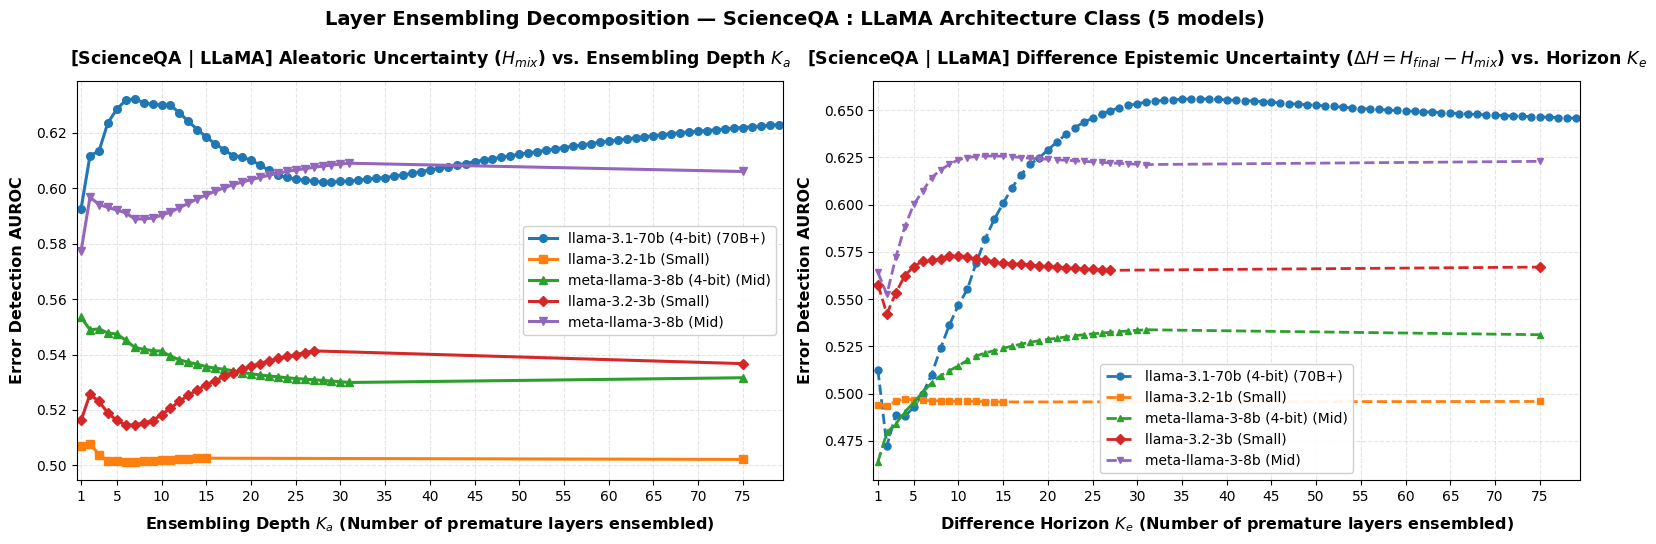

In [31]:
# Block 4.1.1: ScienceQA — LLaMA Architecture Class
plot_depth_sweep_block(sweep_data, target_dataset='scienceqa', target_family='LLaMA')

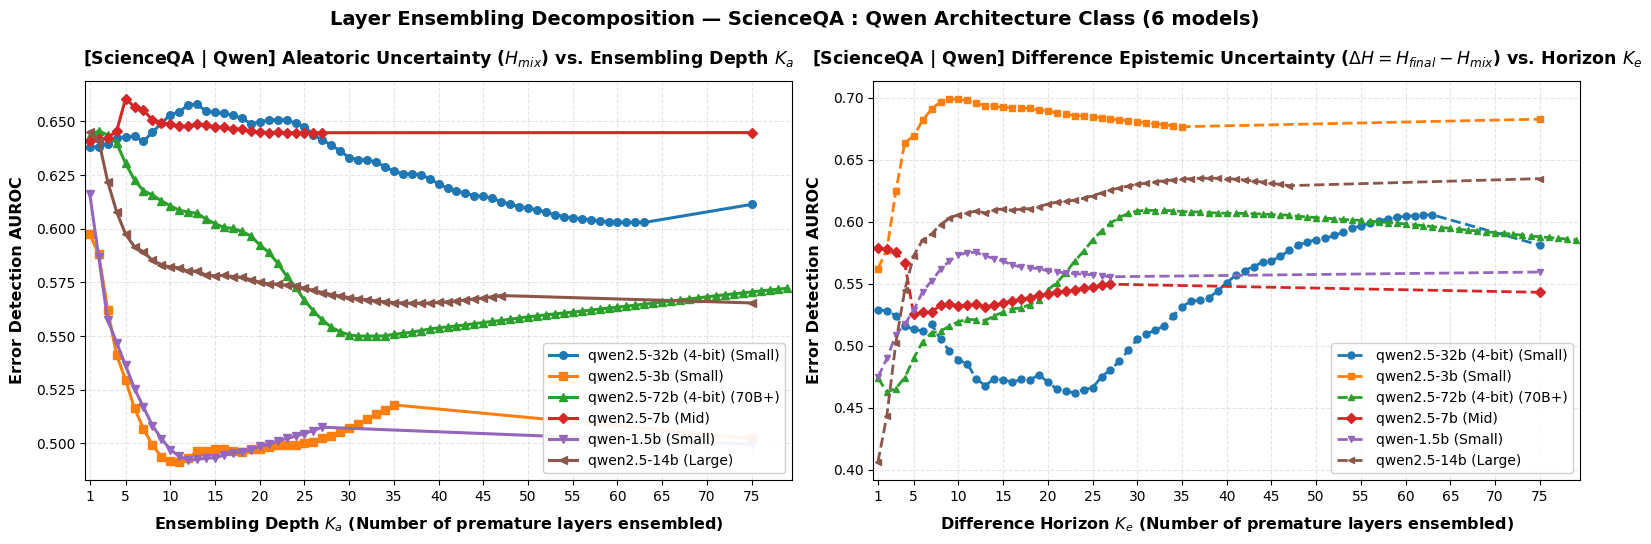

In [32]:
# Block 4.1.2: ScienceQA — Qwen Architecture Class
plot_depth_sweep_block(sweep_data, target_dataset='scienceqa', target_family='Qwen')

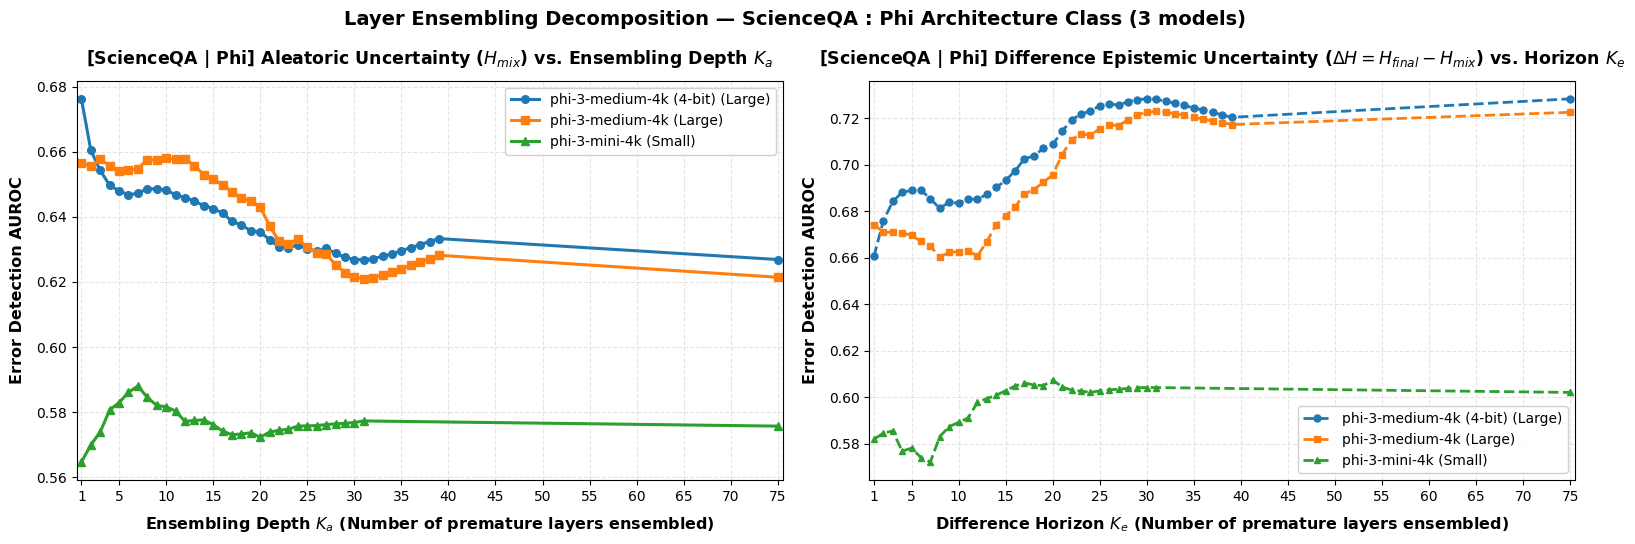

In [33]:
# Block 4.1.3: ScienceQA — Phi Architecture Class
plot_depth_sweep_block(sweep_data, target_dataset='scienceqa', target_family='Phi')

### 4.2 TruthfulQA Blocks (Single Architecture Class per Plot)
Each plot displays only one model architecture family on the `TruthfulQA` benchmark.

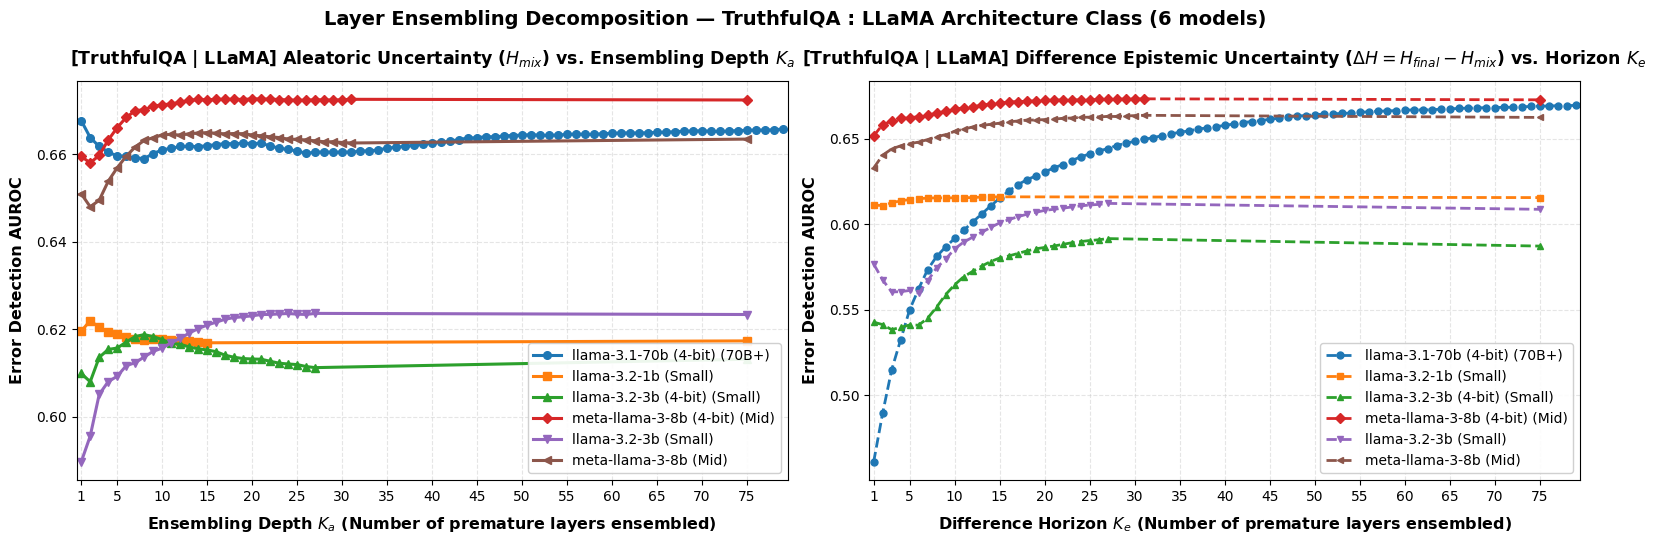

In [34]:
# Block 4.2.1: TruthfulQA — LLaMA Architecture Class
plot_depth_sweep_block(sweep_data, target_dataset='truthfulqa', target_family='LLaMA')

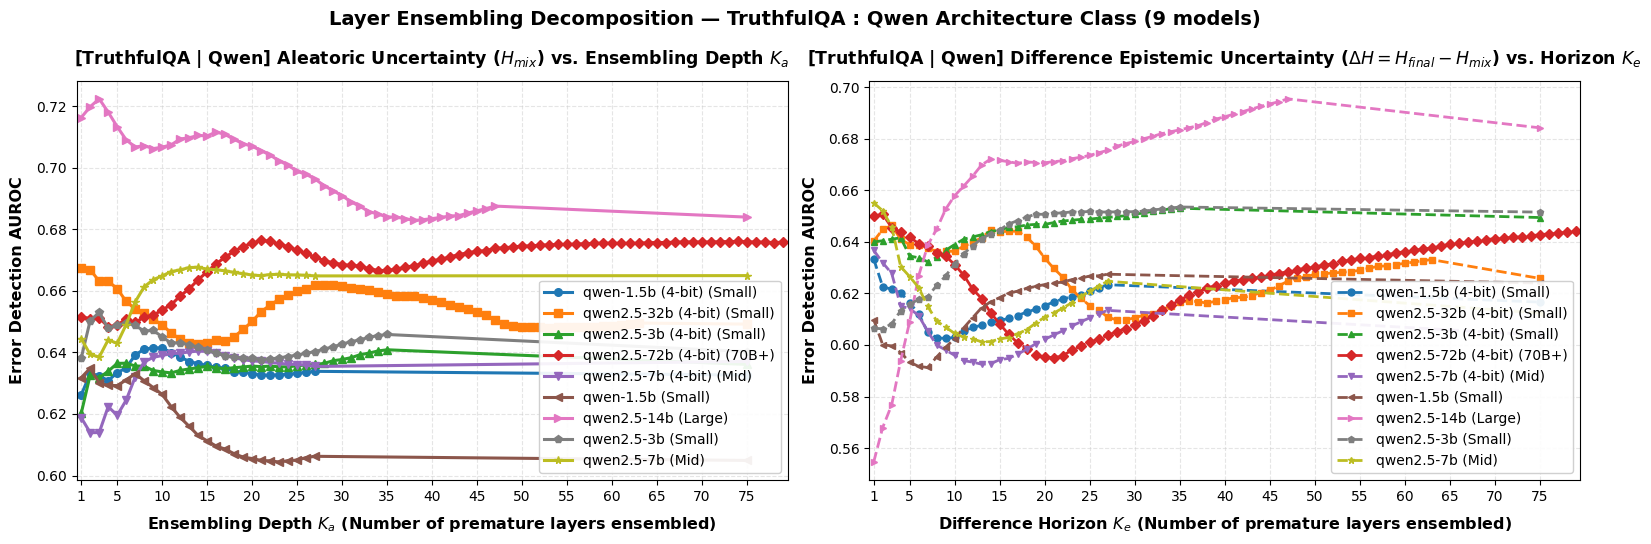

In [35]:
# Block 4.2.2: TruthfulQA — Qwen Architecture Class
plot_depth_sweep_block(sweep_data, target_dataset='truthfulqa', target_family='Qwen')

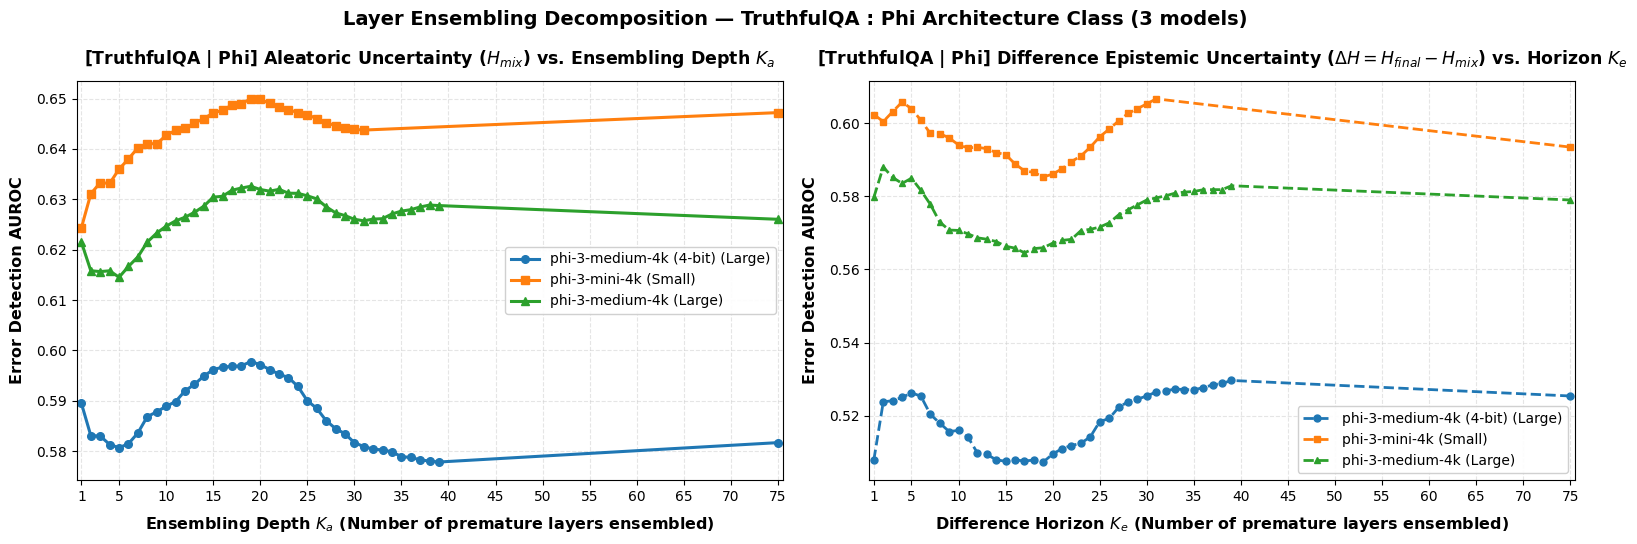

In [36]:
# Block 4.2.3: TruthfulQA — Phi Architecture Class
plot_depth_sweep_block(sweep_data, target_dataset='truthfulqa', target_family='Phi')

### 4.3 Dynamic Block Runner (Any Additional Discovered Datasets & Classes)
Automatically evaluates and renders any additional dataset-family pairings discovered dynamically on the cloud instance.


Plotting 3 additional discovered (Dataset, Model Family) blocks...


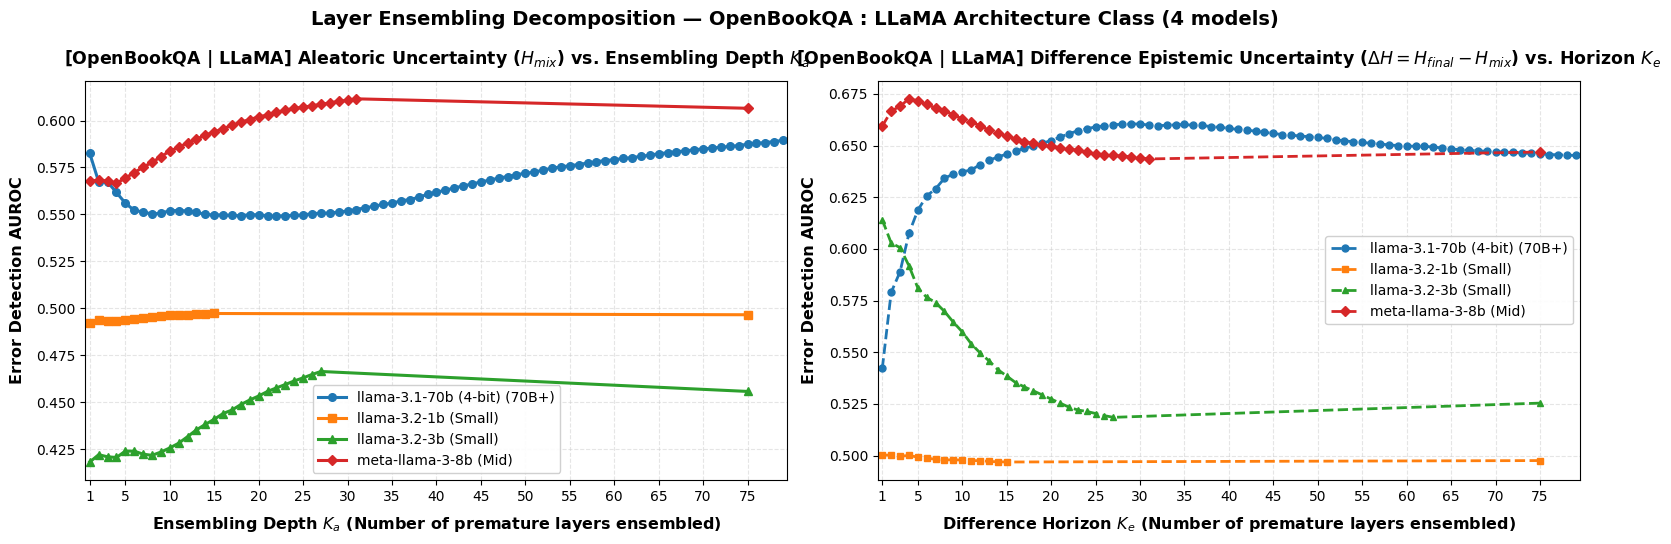

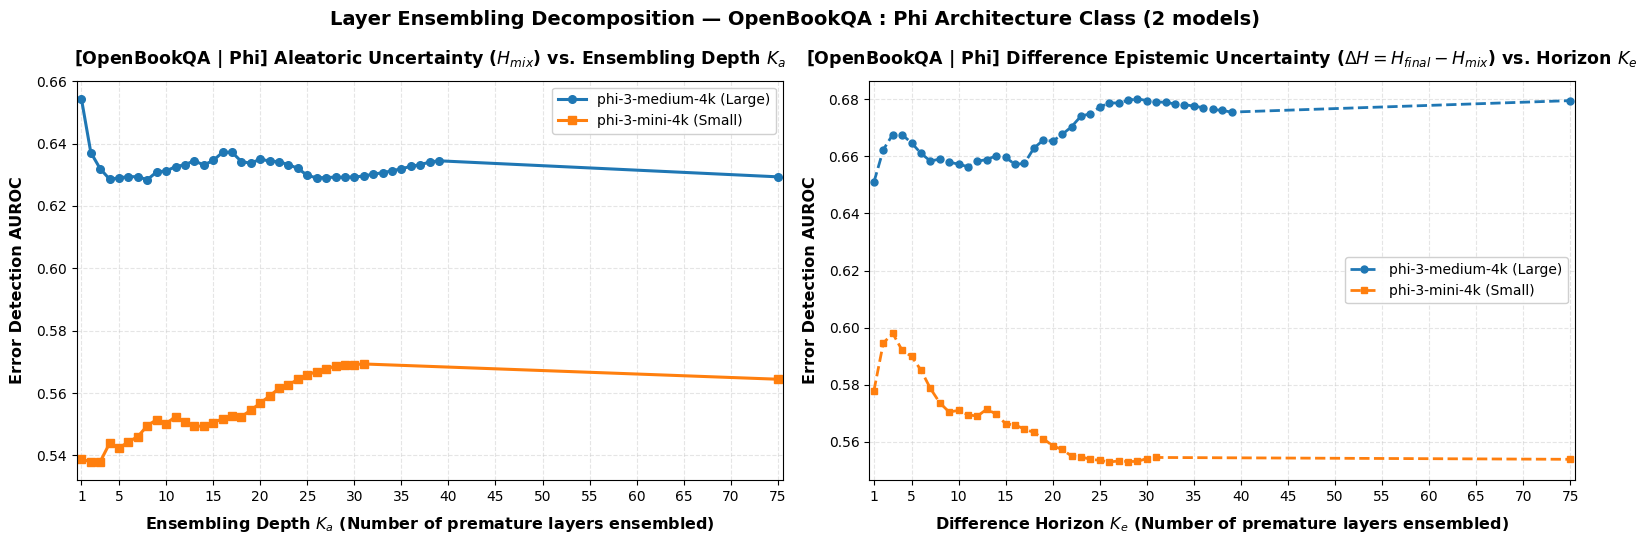

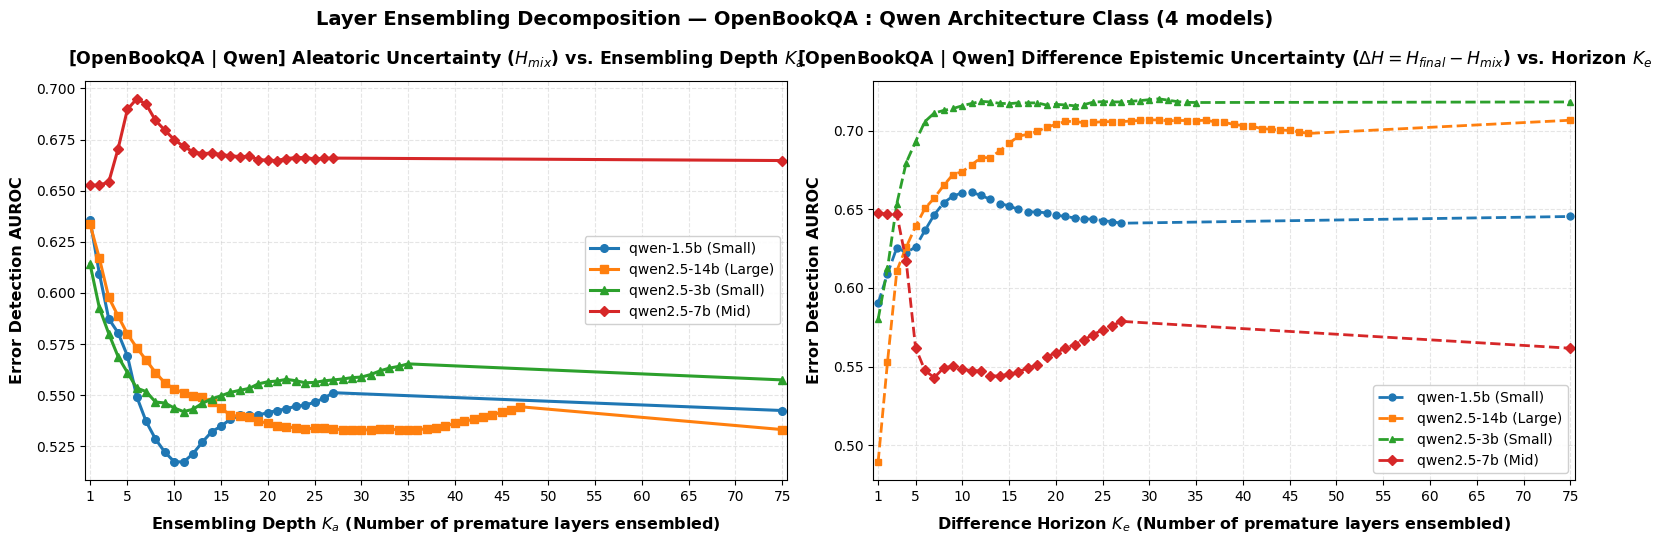

In [25]:
# Dynamic runner for any additional datasets or model classes beyond ScienceQA and TruthfulQA
known_pairs = {
    ("scienceqa", "llama"), ("scienceqa", "qwen"), ("scienceqa", "phi"),
    ("truthfulqa", "llama"), ("truthfulqa", "qwen"), ("truthfulqa", "phi")
}
plot_all_discovered_blocks(sweep_data, exclude_pairs=known_pairs)